# IC ×10: control Sobol y confirmación con nuevas semillas

La comparación cruza dos selectores (PCA + media al 95 % con reconstrucción y Sobol completo) y dos pérdidas (datos+PDE+IC; datos+PDE+10 IC). No hay término BC explícito. PCA usa candidatos fijos, QR directo y 20 snapshots cada cinco pasos del último intervalo de cien; ambos métodos tienen 128 activos, red 3×32, mismo Adam y actualizan puntos cada cien pasos.

Cien pasos uniformes comunes por semilla; IC10 se aplica solo durante los diez mil pasos de continuación, sin reiniciar Adam. Los datos supervisados, particiones de evaluación y 32 nodos IC son comunes. El control baseline conserva exactamente la función de pérdida histórica. La diferencia inicial de puntos activos PCA/Sobol es parte del selector, no se obliga un lote común después del warmup.

**Desarrollo:** semillas 2051–2060; se reutilizan tres combinaciones y se ejecuta Sobol IC10. **Confirmación:** semillas 2071–2080, elegidas antes de ejecutar, cuatro combinaciones nuevas por semilla. Se congela el peso 10 y el protocolo; no se ajustan parámetros usando los resultados de confirmación. Los grupos se presentan separados. El éxito requiere comparar PCA y Sobol bajo el mismo objetivo, no comparar PCA IC10 contra Sobol IC1.

## development

| Selector | Peso IC | Validación RMSE | Prueba RMSE ± DE | Residuo RMS | RMSE IC |
|---|---:|---:|---:|---:|---:|
| pca | 1 | 0.06700 | 0.07144 ± 0.00977 | 0.16801 | 0.08991 |
| sobol | 1 | 0.05530 | 0.05722 ± 0.01961 | 0.31074 | 0.06560 |
| pca | 10 | 0.06186 | 0.05941 ± 0.01769 | 0.23165 | 0.02473 |
| sobol | 10 | 0.05815 | 0.05765 ± 0.03962 | 0.40761 | 0.01720 |

PCA minus Sobol (baseline): diferencia media +0.01422; valores negativos en 2/10 semillas; intervalo bootstrap 95 % [-0.00039, +0.02641].

PCA minus Sobol (ic10): diferencia media +0.00176; valores negativos en 2/10 semillas; intervalo bootstrap 95 % [-0.02381, +0.02117].

IC10 minus baseline (pca): diferencia media -0.01203; valores negativos en 8/10 semillas; intervalo bootstrap 95 % [-0.02427, +0.00091].

IC10 minus baseline (sobol): diferencia media +0.00043; valores negativos en 7/10 semillas; intervalo bootstrap 95 % [-0.01985, +0.02532].
## confirmation

| Selector | Peso IC | Validación RMSE | Prueba RMSE ± DE | Residuo RMS | RMSE IC |
|---|---:|---:|---:|---:|---:|
| pca | 1 | 0.07814 | 0.08236 ± 0.02152 | 0.16229 | 0.10331 |
| sobol | 1 | 0.06318 | 0.06785 ± 0.03464 | 0.37840 | 0.07047 |
| pca | 10 | 0.06078 | 0.06191 ± 0.01464 | 0.24614 | 0.02297 |
| sobol | 10 | 0.05953 | 0.05982 ± 0.04083 | 0.43213 | 0.01974 |

PCA minus Sobol (baseline): diferencia media +0.01451; valores negativos en 3/10 semillas; intervalo bootstrap 95 % [-0.00376, +0.03073].

PCA minus Sobol (ic10): diferencia media +0.00209; valores negativos en 4/10 semillas; intervalo bootstrap 95 % [-0.02733, +0.02672].

IC10 minus baseline (pca): diferencia media -0.02045; valores negativos en 8/10 semillas; intervalo bootstrap 95 % [-0.03654, -0.00634].

IC10 minus baseline (sobol): diferencia media -0.00803; valores negativos en 7/10 semillas; intervalo bootstrap 95 % [-0.04209, +0.02774].

**Comparación**

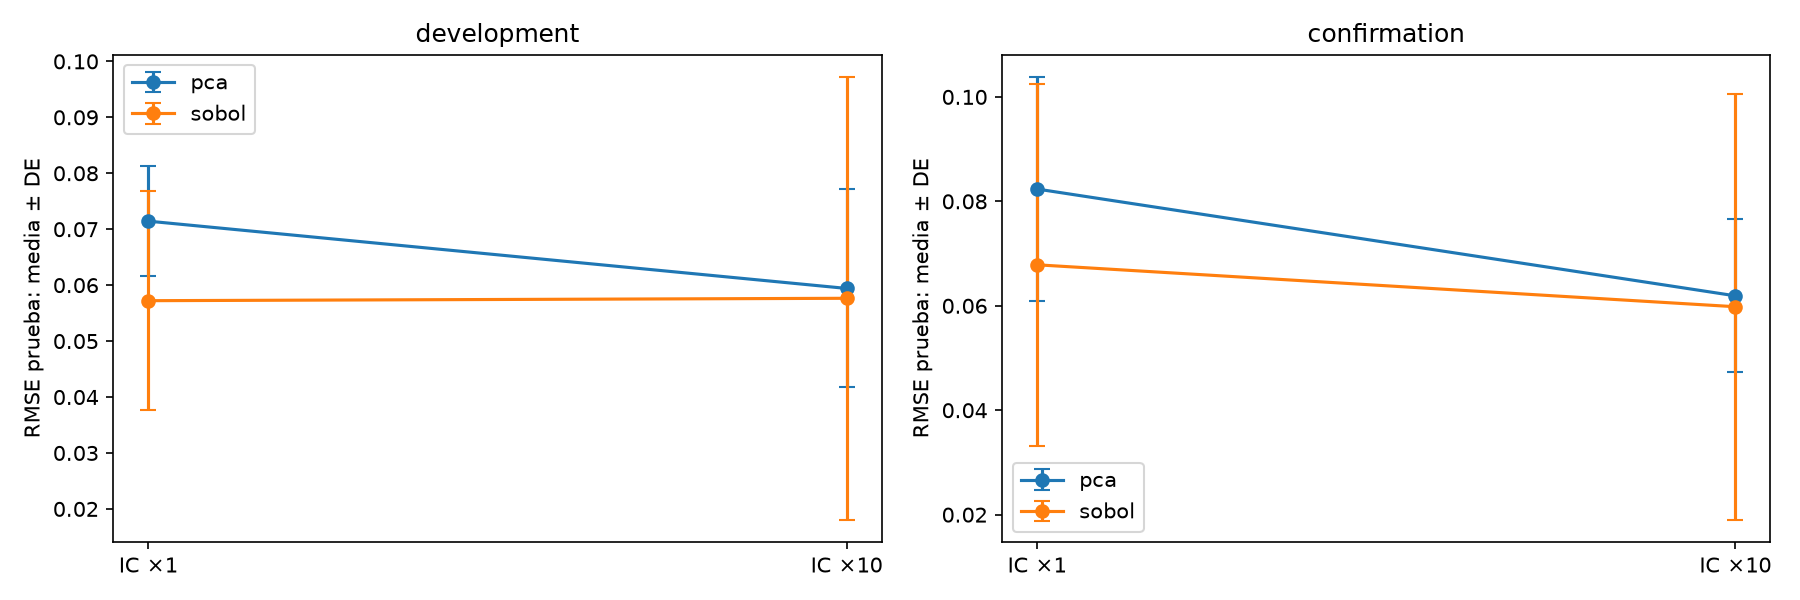

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_confirmation/ic10_sobol_confirmation_10new_v1/comparison.png'), format='png', embed=True))


Los resultados son de modelos terminales a presupuesto prefijado, sin escoger el mejor checkpoint por prueba. El bootstrap pareado usa 20000 remuestras de las diez diferencias por semilla; con diez semillas su incertidumbre puede ser considerable y no corrige multiplicidad. DE describe dispersión entre semillas. No se afirma aceleración: PCA requiere observar candidatos y el instrumental agrega costo.

manifest.json identifica la procedencia; metrics.csv contiene resultados por semilla y summary.json los contrastes pareados. Las referencias reutilizadas y nuevas no deben contarse como ejecuciones independientes adicionales. Los diagnósticos de componentes y gradientes están en cada corrida nueva. Los pesos se aplican después del warmup idéntico, verificado por métricas comunes.

Reproducir: `python scripts/run_collocation_ic_confirmation.py`. Las corridas completas se reutilizan; configuración en pca_collocation/configs/burgers_ic_confirmation.json. Las figuras se incrustan como PNG.